# 01 - Dataset Preparation

This notebook loads and prepares the Fashion-MNIST dataset
for all generative model experiments.

In [11]:
import json
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from torchvision import datasets
from sklearn.model_selection import train_test_split
from pathlib import Path

In [12]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
DATASET_DIR = DATA_DIR / "fashion_mnist"

DATASET_DIR.mkdir(parents=True, exist_ok=True)

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GENERAL_CONFIG = CONFIG["general"]

RANDOM_SEED = GENERAL_CONFIG["random_seed"]
IMAGE_SIZE = GENERAL_CONFIG["image_size"]
BATCH_SIZE = GENERAL_CONFIG["batch_size"]

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Random seed:", RANDOM_SEED)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Project directory: d:\generative-models-comparison
Dataset directory: d:\generative-models-comparison\data\fashion_mnist
Random seed: 42
Image size: 28
Batch size: 128


In [13]:
# Download training dataset
train_dataset = datasets.FashionMNIST(
    root=DATASET_DIR,
    train=True,
    download=True
)

# Download testing dataset
test_dataset = datasets.FashionMNIST(
    root=DATASET_DIR,
    train=False,
    download=True
)

print("Training data:", len(train_dataset))
print("Testing data:", len(test_dataset))

Training data: 60000
Testing data: 10000


In [14]:
# Combine training and testing images
all_images = torch.cat([
    train_dataset.data,
    test_dataset.data
])

# Combine labels
all_labels = torch.cat([
    train_dataset.targets,
    test_dataset.targets
])

print("Total images:", len(all_images))
print("Image shape:", all_images.shape)
print("Total labels:", len(all_labels))

Total images: 70000
Image shape: torch.Size([70000, 28, 28])
Total labels: 70000


In [15]:
# Get dataset split configuration
split_config = GENERAL_CONFIG["data_split"]

train_ratio = split_config["train"]
val_ratio = split_config["validation"]
test_ratio = split_config["test"]

# Create dataset indices
indices = np.arange(len(all_images))

# Split training data and temporary data
train_idx, temp_idx = train_test_split(
    indices,
    test_size=(val_ratio + test_ratio),
    random_state=RANDOM_SEED,
    stratify=all_labels.numpy()
)

# Split temporary data into validation and testing
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=test_ratio / (val_ratio + test_ratio),
    random_state=RANDOM_SEED,
    stratify=all_labels[temp_idx].numpy()
)

# Display dataset sizes
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Training samples: 56000
Validation samples: 7000
Testing samples: 7000


In [16]:
# Create dataset splits
train_images = all_images[train_idx]
train_labels = all_labels[train_idx]

val_images = all_images[val_idx]
val_labels = all_labels[val_idx]

test_images = all_images[test_idx]
test_labels = all_labels[test_idx]

# Add channel dimension
train_images = train_images.unsqueeze(1)
val_images = val_images.unsqueeze(1)
test_images = test_images.unsqueeze(1)

# Check dataset shapes
print("Train shape:", train_images.shape)
print("Validation shape:", val_images.shape)
print("Test shape:", test_images.shape)

Train shape: torch.Size([56000, 1, 28, 28])
Validation shape: torch.Size([7000, 1, 28, 28])
Test shape: torch.Size([7000, 1, 28, 28])


In [17]:
# Define Fashion-MNIST class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))
print("Class names:", class_names)

Number of classes: 10
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


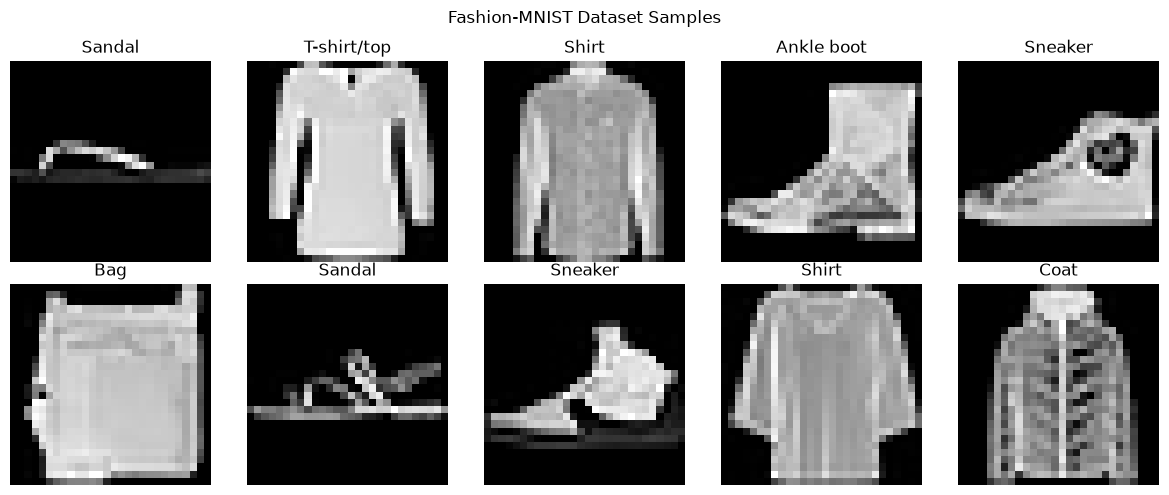

In [18]:
# Visualize Fashion-MNIST samples
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = train_images[i].squeeze(0)

    ax.imshow(image, cmap="gray")
    ax.set_title(class_names[train_labels[i].item()])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Dataset Samples")
plt.tight_layout()
plt.show()

In [19]:
# Save dataset splits
dataset_splits = {
    "train_images": train_images,
    "train_labels": train_labels,
    "val_images": val_images,
    "val_labels": val_labels,
    "test_images": test_images,
    "test_labels": test_labels
}

torch.save(
    dataset_splits,
    DATASET_DIR / "fashion_mnist_splits.pt"
)

print("Dataset splits saved successfully!")
print("Saved location:", DATASET_DIR / "fashion_mnist_splits.pt")

Dataset splits saved successfully!
Saved location: d:\generative-models-comparison\data\fashion_mnist\fashion_mnist_splits.pt
